# κ-GNAR on power-law networks: how κ shapes the dynamics

On an unweighted, undirected graph with no isolated nodes, the `KappaGNAR` model is

$$X_t - \mu = \Phi\,(X_{t-1}-\mu) + \varepsilon_t, \qquad \Phi = \alpha I + b\,\frac{D^{-\kappa}A}{\rho_\kappa}, \qquad \varepsilon_t \sim N(0, \sigma^2 I).$$

- $D$ is the diagonal matrix of degrees, and $\kappa \in [0,1]$ controls how the neighbour sum is normalised: κ = 1 gives the neighbour average (standard GNAR), κ = 0 the raw sum.
- $\rho_\kappa$ is the spectral radius of $D^{-\kappa}A$, so the network part of $\Phi$ has spectral radius exactly $|b|$ for every κ.

This notebook shows three things, for as many values of κ as you like:
1. the degree distribution of the graph;
2. the **total neighbour weight** of each node (the row sums of the network part of $\Phi$) against degree;
3. the **marginal variance** of each node against degree.

Change the **Settings** cell and re-run everything. Colours encode κ on a sequential scale, light for κ = 0 to dark for κ = 1.

In [1]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

from gnar import KappaGNAR
from gnar.utils.graphs import powerlaw_configuration_graph

T_START = time.perf_counter()

# ---- Plot style: thin marks, recessive axes ----
BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1-2 (degree-distribution plot only)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
KAPPA_CMAP = ListedColormap(plt.cm.Blues(np.linspace(0.3, 1.0, 256)))   # sequential, one hue, light -> dark
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "legend.frameon": False, "axes.titlesize": 11, "axes.titleweight": "bold",
})


def kappa_colors(kappas):
    # One colour per kappa, set by its value on the sequential scale (not by its position in the list)
    return [KAPPA_CMAP(float(k)) for k in kappas]


def add_kappa_colorbar(fig, ax, kappas):
    # Discrete colorbar with one band per plotted kappa, labelled with the kappa values
    kappas = np.sort(np.asarray(kappas, dtype=float))
    if len(kappas) > 1:
        mids = (kappas[1:] + kappas[:-1]) / 2
        bounds = np.r_[2 * kappas[0] - mids[0], mids, 2 * kappas[-1] - mids[-1]]
    else:
        bounds = np.array([kappas[0] - 0.05, kappas[0] + 0.05])
    cmap = ListedColormap(kappa_colors(kappas))
    cb = fig.colorbar(ScalarMappable(norm=BoundaryNorm(bounds, len(kappas)), cmap=cmap), ax=ax, ticks=kappas,
                      shrink=0.9, pad=0.02)
    cb.set_label(r"$\kappa$")
    cb.ax.set_yticklabels([f"{k:g}" for k in kappas])
    return cb

## Settings
Runtime is dominated by the variance plot: one eigendecomposition per value of κ. That's about 1 min per κ at `D_NODES = 10_000`, about 8 s at 5,000, and under 1 s at 2,000. The other plots take seconds at any of these sizes.

In [2]:
# Graph: erased configuration model with P(k) ~ k^-gamma on [k_min, k_max]
D_NODES = 10_000       # requested number of nodes
GAMMA = 2.5            # power-law exponent
K_MIN = 2              # minimum degree
K_MAX = None           # None -> floor(sqrt(D_NODES)), the structural cutoff; D_NODES - 1 for uncapped
GRAPH_SEED = 1

# Model (shared by all kappa)
ALPHA, B, SIGMA_2 = 0.3, 0.6, 1.0

# Values of kappa to compare: any number of values in [0, 1]
KAPPAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Variance plot: also shade the 10-90% range of the variances at each degree
SHOW_SPREAD = False

## 1. Degree distribution
`powerlaw_configuration_graph` samples degrees from a discrete power law, pairs edge stubs at random (`networkx.configuration_model`), removes self-loops and multi-edges, and keeps the largest connected component. The plot compares the default graph, whose degrees are capped at $\sqrt{d}$, with an uncapped one.

{'n_requested': 10000, 'n_nodes': 10000, 'n_edges': 20719, 'self_loops_removed': 8, 'multi_edges_removed': 25, 'nodes_removed': 0}
degrees: min=1, median=2, mean=4.14, max=94


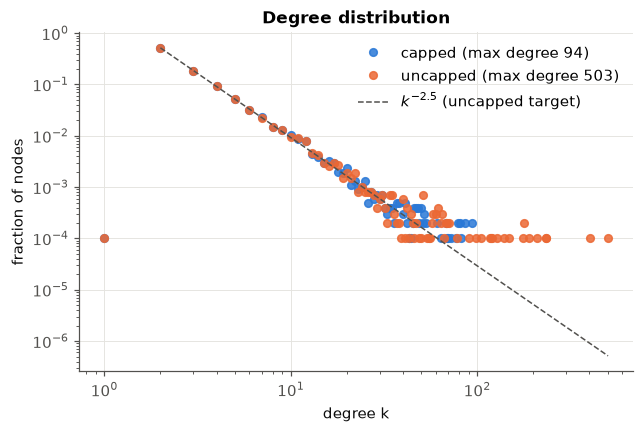

In [3]:
G, info = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=K_MAX, seed=GRAPH_SEED, return_info=True)
A = nx.to_scipy_sparse_array(G, nodelist=range(G.number_of_nodes()), format="csr")   # sparse adjacency matrix
deg = np.asarray(A.sum(axis=1)).ravel()
d = A.shape[0]
print(info)
print(f"degrees: min={deg.min():.0f}, median={np.median(deg):.0f}, mean={deg.mean():.2f}, max={deg.max():.0f}")

G_unc = powerlaw_configuration_graph(D_NODES, gamma=GAMMA, k_min=K_MIN, k_max=D_NODES - 1, seed=GRAPH_SEED)
deg_unc = np.array([k for _, k in G_unc.degree])

fig, ax = plt.subplots(figsize=(6.5, 4))
for degs, label, color in [(deg, f"capped (max degree {int(deg.max())})", BLUE),
                           (deg_unc, f"uncapped (max degree {deg_unc.max()})", ORANGE)]:
    k, counts = np.unique(degs, return_counts=True)
    ax.loglog(k, counts / counts.sum(), "o", ms=5, color=color, label=label, alpha=0.85)
k_line = np.arange(K_MIN, deg_unc.max() + 1)
law = k_line ** -GAMMA / np.sum(k_line ** -GAMMA)
ax.loglog(k_line, law, color=MUTED, lw=1, ls="--", label=fr"$k^{{-{GAMMA}}}$ (uncapped target)")
ax.set_xlabel("degree k"); ax.set_ylabel("fraction of nodes")
ax.set_title("Degree distribution")
ax.legend()
plt.show()

## 2. Total neighbour weight
Row $i$ of the network part of $\Phi$ sums to $\dfrac{b}{\rho_\kappa}\, d_i^{\,1-\kappa}$: the total weight node $i$ puts on its neighbours.
- κ = 1: every node gets the same total, $b$.
- κ < 1: the total grows with degree, so hubs lean harder on their neighbours and leaves less. Since $b$ fixes the spectral radius, $\rho_\kappa$ rescales the whole curve.

Computing $\rho_\kappa$ only needs the extreme eigenvalue of a sparse matrix, so this plot is fast for any graph size.

6 models (rho_kappa via sparse Lanczos) in 0.10s


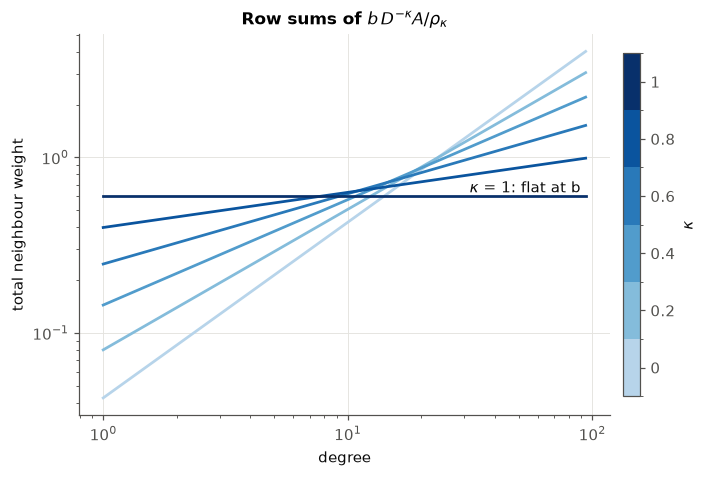

In [4]:
t0 = time.perf_counter()
models = {k: KappaGNAR(A, alpha=ALPHA, b=B, kappa=k, sigma_2=SIGMA_2) for k in KAPPAS}
print(f"{len(KAPPAS)} models (rho_kappa via sparse Lanczos) in {time.perf_counter() - t0:.2f}s")

degree_values = np.unique(deg)
first_node = np.array([np.flatnonzero(deg == k)[0] for k in degree_values])   # one node per degree value

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kappa, color in zip(KAPPAS, kappa_colors(KAPPAS)):
    row_sums = np.asarray(models[kappa].phi().sum(axis=1)).ravel() - ALPHA      # phi() is sparse
    ax.plot(degree_values, row_sums[first_node], "-", color=color)              # depends on a node only via its degree
if 1.0 in KAPPAS:
    ax.text(degree_values.max(), B, r"$\kappa$ = 1: flat at b ", color=INK, va="bottom", ha="right")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("degree"); ax.set_ylabel("total neighbour weight")
ax.set_title(r"Row sums of $b\,D^{-\kappa}A/\rho_\kappa$")
add_kappa_colorbar(fig, ax, KAPPAS)
plt.show()

On log-log axes each curve is a straight line with slope $1-\kappa$. The κ = 1 line is flat at $b$.

## 3. Variance by degree
`marginal_variances()` computes the exact stationary variances $\operatorname{Var}(X_i)$ from one symmetric eigendecomposition per κ. Each line shows the mean variance over the nodes with a given degree. Set `SHOW_SPREAD = True` to also shade the 10–90% range at each degree, which comes from the nodes' different positions in the graph.

In [5]:
variances = {}
for kappa in KAPPAS:
    t0 = time.perf_counter()
    variances[kappa] = models[kappa].marginal_variances().to_numpy()
    models[kappa].clear_cache()                                   # free the eigendecomposition (O(d^2) memory)
    print(f"kappa = {kappa:g}: variances in {time.perf_counter() - t0:.1f}s")

kappa = 0: variances in 68.9s


kappa = 0.2: variances in 67.7s


kappa = 0.4: variances in 67.7s


kappa = 0.6: variances in 67.8s


kappa = 0.8: variances in 68.8s


kappa = 1: variances in 68.7s


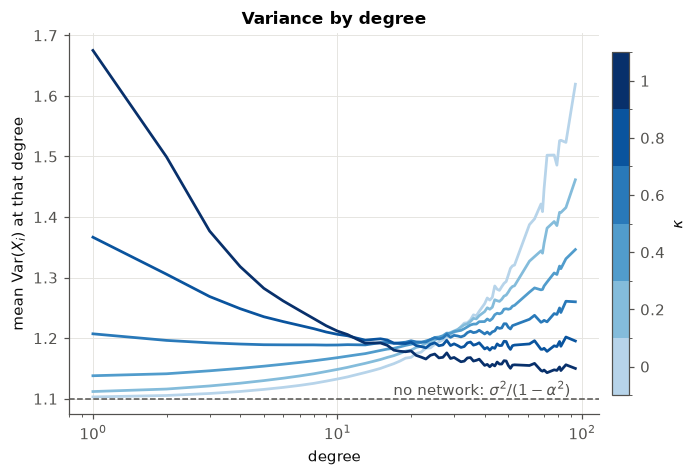

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kappa, color in zip(KAPPAS, kappa_colors(KAPPAS)):
    v = variances[kappa]
    mean = np.array([v[deg == k].mean() for k in degree_values])
    ax.plot(degree_values, mean, "-", color=color)
    if SHOW_SPREAD:
        lo, hi = np.array([np.quantile(v[deg == k], [0.1, 0.9]) for k in degree_values]).T
        ax.fill_between(degree_values, lo, hi, color=color, alpha=0.12, lw=0)
ax.axhline(SIGMA_2 / (1 - ALPHA ** 2), color=MUTED, lw=1, ls="--")
ax.text(degree_values.max(), SIGMA_2 / (1 - ALPHA ** 2), r"no network: $\sigma^2/(1-\alpha^2)$ ", color=MUTED,
        va="bottom", ha="right")
ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel(r"mean Var$(X_i)$ at that degree")
ax.set_title("Variance by degree")
add_kappa_colorbar(fig, ax, KAPPAS)
plt.show()

Two effects pull in opposite directions.
- **Total weight.** Node $i$'s total neighbour weight is $(b/\rho_\kappa)\,d_i^{1-\kappa}$ (section 2), so for κ < 1 hubs lean harder on their neighbours.
- **Averaging.** When neighbours are close to independent, the neighbour term has variance $\operatorname{Var}(d_i^{-\kappa}\sum_{j} X_j) \approx d_i^{1-2\kappa}\, v$, where $v$ is a typical node variance.

Combining them:
- **κ near 1 (average):** a leaf "averages" a single neighbour and takes on all of its noise, while a hub's average over many neighbours cancels most of it. So **leaves have the largest variance**.
- **κ near 0 (sum):** hubs add up many neighbours, so **hubs have the largest variance**.
- **κ = 1/2:** the exponent $1 - 2\kappa$ vanishes, so the neighbour input has (roughly) the same variance at every degree. The flattest curve is the one closest to κ = 1/2. It needn't be exactly 1/2, because the approximation ignores correlations between neighbours.

At high degrees the curves are jagged because only a few nodes have each of those degrees.

Because $b$ is spectrally normalised, the network's dominant mode has the same strength ($|b|$) for every κ. κ only changes how that strength is spread across nodes.

In [7]:
print(f"Total runtime: {time.perf_counter() - T_START:.0f}s")

Total runtime: 410s
